# VIS4AI · Notebook 03: Where small models fail, and what the reasoning really does
*Visualizations of the AI-aided pair (see [`AI_USAGE_LOG.md`](../AI_USAGE_LOG.md)).*

Notebook 02 compares the two models **on average** (accuracy, tokens, correlations). This notebook looks at
**single problems and inside the outputs** of the same run (`run_4`, 50 GSM8K problems):

| Model | What it is |
|---|---|
| **Qwen2.5-Math-1.5B** | math *base* model: short textbook-style solutions, often with Python code |
| **R1-Distill-1.5B** | the *same* model, fine-tuned on reasoning traces of DeepSeek-R1: thinks at length in `<think> … </think>` first |

Because R1-Distill **is** Qwen2.5-Math plus reasoning training, every difference below is an effect of that training.

**Story line**
1. **Who fails where?** The failures are nested: R1 solves everything Qwen solves, plus 3 more.
2. **Why do they fail?** Every failure, labelled by type. Reasoning fixes *calculation* errors, not *understanding* errors.
3. **Case studies:** the exact words where it goes wrong.
4. **Inside R1's thinking:** when does the correct answer appear, and what happens afterwards?
5. **Experiment A, early answering:** stop R1's thinking early and force an answer. How much thinking is needed?
6. **Experiment B, rewording:** are the shared mistakes caused by the wording of the questions?
7. **Summary**

### How to run
* **Colab:** `Runtime → Run all`. Results are read from (and the experiments saved to) Google Drive `VIS4AI/results/<RUN>`.
* **Locally:** put the run folder in `data/` at the repo root (e.g. `data/run_4/`).
* Sections 1–4 only need the saved results. Sections 5–6 need a GPU (Colab T4, or Apple Silicon) **only if their
  result files `nb03_*.jsonl` are not in the run folder yet**; otherwise they are just loaded.

## 0. Setup and loading the results

In [1]:
import json
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

RUN = "run_4_2026-11-08_15-40"   # the run analysed in Notebook 02

try:                               # on Colab: read from Google Drive
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = Path("/content/drive/MyDrive/VIS4AI/results") / RUN
except ImportError:                # locally: read from data/ in the repo
    data_dir = Path.cwd().parent / "data" if Path.cwd().name == "notebooks" else Path.cwd() / "data"
    RESULTS_DIR = next(p for p in [data_dir / RUN, data_dir / RUN.split("_2")[0]] if p.exists())
print("Reading results from:", RESULTS_DIR)

R1, QWEN = "R1-Distill-1.5B", "Qwen2.5-Math-1.5B"
MODELS = {"r1-distill": R1, "qwen-math": QWEN}   # file name -> short label

# Colours: outcome = status colours, always paired with a symbol so colour is never the only cue
COLORS  = {"correct": "#0ca30c", "wrong": "#d03b3b", "cut off": "#a8a79e", "no answer": "#e1e0d9"}
SYMBOLS = {"correct": "✓", "wrong": "✗", "cut off": "…", "no answer": "–"}
INK, INK_MUTED, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e1e0d9"
BLUE, BLUE_LIGHT = "#2a78d6", "#b9d3f3"              # R1's thinking: before / after the answer first appears
MARK_KEY, MARK_BAD, MARK_GOOD = "#fde3a7", "#f6c7c7", "#c9ecc9"   # text highlights

plt.rcParams.update({"text.parse_math": False,       # questions contain "$" signs
                     "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED,
                     "ytick.color": INK_MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})

Reading results from: <repo>/data/run_4


In [2]:
def outcome(row):
    # Same categories as the comparison table in Notebook 01
    if not row["finished"]:
        return "cut off"
    if row["answer"] is None or pd.isna(row["answer"]):
        return "no answer"
    return "correct" if row["correct"] else "wrong"


def thinking(text):
    # R1's thinking = everything before </think> (all of it if it was cut off while thinking)
    return text.split("</think>")[0]


results = []
for key, label in MODELS.items():
    df = pd.read_json(RESULTS_DIR / f"{key}.jsonl", lines=True, dtype={"gold": str, "answer": str})
    df["model"] = label
    df["outcome"] = df.apply(outcome, axis=1)
    results.append(df)
results = pd.concat(results, ignore_index=True)

# One row per problem, one column per model
outcomes = results.pivot(index="id", columns="model", values="outcome")[[R1, QWEN]]
answers  = results.pivot(index="id", columns="model", values="answer")[[R1, QWEN]]
outputs  = results.pivot(index="id", columns="model", values="output")[[R1, QWEN]]
tokens   = results.pivot(index="id", columns="model", values="n_tokens")[[R1, QWEN]]
problems = results.drop_duplicates("id").set_index("id")[["question", "gold"]]

results.groupby("model")["outcome"].value_counts().unstack(fill_value=0)

outcome,correct,cut off,wrong
model,,,
Qwen2.5-Math-1.5B,40,2,8
R1-Distill-1.5B,43,3,4


## 1. Who fails where?
The table counts the problems by the outcome of **both** models at once (rows: R1-Distill, columns: Qwen2.5-Math).

In [3]:
pd.crosstab(outcomes[R1], outcomes[QWEN], margins=True, margins_name="total")

Qwen2.5-Math-1.5B,correct,cut off,wrong,total
R1-Distill-1.5B,,,,
correct,40,0,3,43
cut off,0,1,2,3
wrong,0,1,3,4
total,40,2,8,50


Each column below is one problem, sorted into groups by what happened to the two models.
`✓` correct, `✗` wrong, `…` cut off at the token limit.

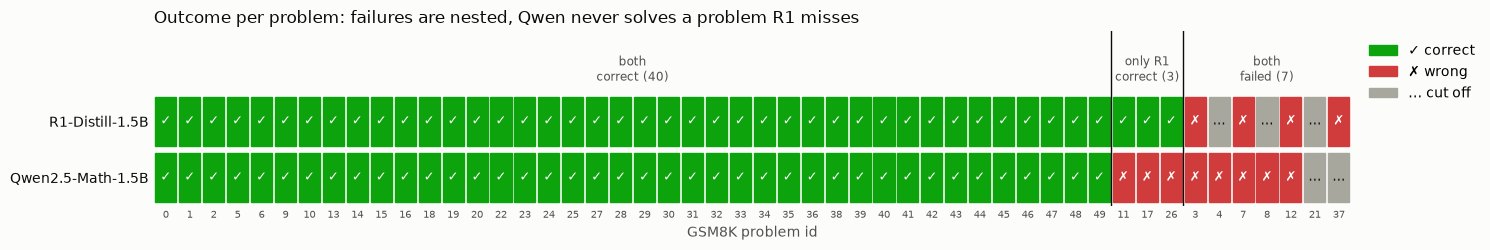

In [4]:
def group(row):
    ok_r1, ok_qwen = row[R1] == "correct", row[QWEN] == "correct"
    if ok_r1 and ok_qwen:
        return "both correct"
    if ok_r1:
        return f"only {R1} correct"
    if ok_qwen:
        return f"only {QWEN} correct"
    return "both failed"


GROUP_ORDER = ["both correct", f"only {R1} correct", f"only {QWEN} correct", "both failed"]
groups = outcomes.apply(group, axis=1)
order = sorted(outcomes.index, key=lambda i: (GROUP_ORDER.index(groups[i]), i))

fig, ax = plt.subplots(figsize=(15, 2.6))
for x, pid in enumerate(order):
    for y, model in enumerate([R1, QWEN]):
        o = outcomes.loc[pid, model]
        ax.add_patch(plt.Rectangle((x + 0.06, y + 0.06), 0.88, 0.88, color=COLORS[o]))   # gap between cells
        ax.text(x + 0.5, y + 0.5, SYMBOLS[o], ha="center", va="center", fontsize=9,
                color=INK if o in ("cut off", "no answer") else "white")

x = 0
for g in GROUP_ORDER:                      # group labels and separators above the grid
    n = int((groups == g).sum())
    if n == 0:
        continue
    label = g.replace(R1, "R1").replace(QWEN, "Qwen").replace(" correct", "\ncorrect").replace("both failed", "both\nfailed")
    ax.text(x + n / 2, -0.15, f"{label} ({n})", ha="center", va="bottom", fontsize=8.5, color=INK_MUTED)
    if x > 0:
        ax.axvline(x, color=INK, lw=1)
    x += n

ax.set_xlim(0, len(order))
ax.set_ylim(2, -1.1)
ax.set_yticks([0.5, 1.5], [R1, QWEN], color=INK)
ax.set_xticks(np.arange(len(order)) + 0.5, order, fontsize=7)
ax.set_xlabel("GSM8K problem id")
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(handles=[Patch(color=c, label=f"{SYMBOLS[o]} {o}") for o, c in COLORS.items() if (outcomes == o).any().any()],
          loc="upper left", bbox_to_anchor=(1.005, 1), frameon=False)
ax.set_title("Outcome per problem: failures are nested, Qwen never solves a problem R1 misses",
             loc="left", fontsize=12, color=INK)
plt.tight_layout()
plt.show()

**Takeaway:** 40 problems are easy for both. R1 adds 3 problems on top, and loses none. The remaining 7 are hard for
*both* models, so the hard problems are a property of the questions, not of one model.

## 2. Why do they fail? Every failure, labelled by type
We read the full output of each of the 17 failures (10 Qwen, 7 R1) and gave it one type, from *understanding* the
question (top rows) to *carrying out* the solution (bottom rows). The short evidence for each label is in the table below the plot.

*The labels were proposed by the AI (Claude) after reading every output and **must be checked by the team**
(open an output with the cell at the end of this section).*

In [5]:
FAILURE_TYPES = ["misread a number", "misunderstood the story", "ambiguous question",
                 "made-up code output", "went in circles (cut off)", "repeated itself (cut off)"]

FAILURES = [  # (model, problem id, type, evidence)
    (R1,   3,  "misread a number",          "restates the question as '3 sprints a week': 3 × 60 = 180"),
    (QWEN, 3,  "misread a number",          "sprints_per_week = 3: 3 × 60 = 180"),
    (QWEN, 4,  "misread a number",          "takes 3 cups per chicken per *meal* (not per day): 180 − 40 = 140"),
    (R1,   7,  "misunderstood the story",   "reads 40% as 'halfway' and adds a second 20-min restart: 100 + 20 + 20"),
    (QWEN, 7,  "misunderstood the story",   "plans a 'second restart': 140"),
    (QWEN, 8,  "misunderstood the story",   "adds the drive back home to the distance away: 180 + 15 + 120 = 315"),
    (R1,   12, "ambiguous question",        "finds that year 13 is the first year with profit, but answers 12 (break-even)"),
    (QWEN, 12, "ambiguous question",        "break-even 90 / 7.5 = 12, while the gold answer counts the first year with profit"),
    (R1,   37, "ambiguous question",        "the question says he sells *all* his toys, so it answers 0 sets left"),
    (QWEN, 11, "made-up code output",       "correct code, but writes the output 716 (true result 694)"),
    (QWEN, 17, "made-up code output",       "correct code, but writes the output 52500 (true result 57500)"),
    (QWEN, 26, "made-up code output",       "correct code, but writes the output 234.0 (true result 243, digits swapped)"),
    (R1,   4,  "went in circles (cut off)", "unsure if 3 cups are per meal or per day, keeps re-deciding until 8192 tokens"),
    (R1,   8,  "went in circles (cut off)", "tries 20, 115, … miles and re-reads the question until 8192 tokens"),
    (R1,   21, "went in circles (cut off)", "mixes up whose son it is and keeps finding contradictions until 8192 tokens"),
    (QWEN, 21, "repeated itself (cut off)", "sets up a contradicting equation and restarts the same steps until 2048 tokens"),
    (QWEN, 37, "repeated itself (cut off)", "writes the same sentence over and over until 2048 tokens"),
]
failures = pd.DataFrame(FAILURES, columns=["model", "id", "type", "evidence"])

# Every failure of the run must have exactly one label
labelled = set(zip(failures["model"], failures["id"]))
actual = {(m, i) for i in outcomes.index for m in [R1, QWEN] if outcomes.loc[i, m] != "correct"}
assert labelled == actual, f"missing: {actual - labelled}, not a failure: {labelled - actual}"

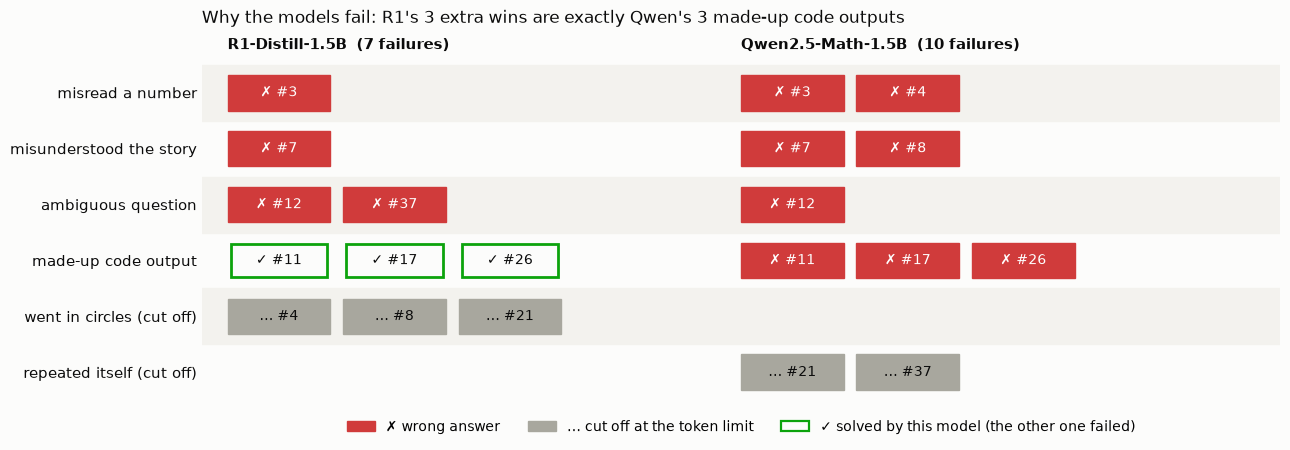

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.6))
COL_X = {R1: 0.0, QWEN: 1.0}            # each model gets one unit of width; chips are placed left to right
CHIP_W, CHIP_H, STEP = 0.2, 0.64, 0.225

for row, ftype in enumerate(FAILURE_TYPES):
    if row % 2 == 0:   # zebra band to guide the eye along a row
        ax.add_patch(plt.Rectangle((-0.05, row - 0.5), 2.1, 1, color="#f3f2ee", zorder=0))
    for model, x0 in COL_X.items():
        other = QWEN if model == R1 else R1
        ids = failures[(failures.type == ftype) & (failures.model == model)]["id"].tolist()
        # problems the OTHER model failed with this type, but this model solved: hollow ✓ chip
        solved = [i for i in failures[(failures.type == ftype) & (failures.model == other)]["id"]
                  if outcomes.loc[i, model] == "correct"]
        for k, pid in enumerate(ids + solved):
            x = x0 + k * STEP
            if pid in ids:
                o = outcomes.loc[pid, model]
                ax.add_patch(plt.Rectangle((x, row - CHIP_H / 2), CHIP_W, CHIP_H, color=COLORS[o]))
                ax.text(x + CHIP_W / 2, row, f"{SYMBOLS[o]} #{pid}", ha="center", va="center", fontsize=10,
                        color="white" if o == "wrong" else INK)
            else:
                ax.add_patch(plt.Rectangle((x + 0.006, row - CHIP_H / 2 + 0.03), CHIP_W - 0.012, CHIP_H - 0.06,
                                           fc=SURFACE, ec=COLORS["correct"], lw=2))
                ax.text(x + CHIP_W / 2, row, f"✓ #{pid}", ha="center", va="center", fontsize=10, color=INK)

ax.set_yticks(range(len(FAILURE_TYPES)), FAILURE_TYPES, fontsize=10.5, color=INK)
ax.set_ylim(len(FAILURE_TYPES) - 0.5, -1.0)
ax.set_xlim(-0.05, 2.05)
for model, x0 in COL_X.items():
    n = (failures.model == model).sum()
    ax.text(x0, -0.85, f"{model}  ({n} failures)", fontsize=11, weight="bold", color=INK, va="center")
ax.set_xticks([])
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(handles=[Patch(color=COLORS["wrong"], label="✗ wrong answer"),
                   Patch(color=COLORS["cut off"], label="… cut off at the token limit"),
                   Patch(fc=SURFACE, ec=COLORS["correct"], lw=1.6, label="✓ solved by this model (the other one failed)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False)
ax.set_title("Why the models fail: R1's 3 extra wins are exactly Qwen's 3 made-up code outputs",
             loc="left", fontsize=12, color=INK, pad=10)
plt.tight_layout()
plt.show()

In [7]:
pd.set_option("display.max_colwidth", 120)
failures.assign(gold=failures["id"].map(problems["gold"]),
                answer=[answers.loc[i, m] for m, i in zip(failures["model"], failures["id"])]
                ).sort_values(["type", "id"], key=lambda s: s.map(FAILURE_TYPES.index) if s.name == "type" else s
                ).set_index(["type", "id", "model"])[["gold", "answer", "evidence"]]

gold answer  \
type                      id model                             
misread a number          3  R1-Distill-1.5B      540    180   
                             Qwen2.5-Math-1.5B    540    180   
                          4  Qwen2.5-Math-1.5B     20    140   
misunderstood the story   7  R1-Distill-1.5B      160    140   
                             Qwen2.5-Math-1.5B    160    140   
                          8  Qwen2.5-Math-1.5B     45    315   
ambiguous question        12 R1-Distill-1.5B       13     12   
                             Qwen2.5-Math-1.5B     13     12   
                          37 R1-Distill-1.5B        2      0   
made-up code output       11 Qwen2.5-Math-1.5B    694    716   
                          17 Qwen2.5-Math-1.5B  57500  52500   
                          26 Qwen2.5-Math-1.5B    243    234   
went in circles (cut off) 4  R1-Distill-1.5B       20    NaN   
                          8  R1-Distill-1.5B       45    NaN   
                          21 R1-Distill-1.5B       14    NaN   
repeated itself (cut off) 21 Qwen2.5-Math-1.5B     14    NaN   
                          37 Qwen2.5-Math-1.5B      2    NaN   

                                                                                                                         evidence  
type                      id model                                                                                                 
misread a number          3  R1-Distill-1.5B                            restates the question as '3 sprints a week': 3 × 60 = 180  
                             Qwen2.5-Math-1.5B                                                 sprints_per_week = 3: 3 × 60 = 180  
                          4  Qwen2.5-Math-1.5B                  takes 3 cups per chicken per *meal* (not per day): 180 − 40 = 140  
misunderstood the story   7  R1-Distill-1.5B               reads 40% as 'halfway' and adds a second 20-min restart: 100 + 20 + 20  
                             Qwen2.5-Math-1.5B                                                      plans a 'second restart': 140  
                          8  Qwen2.5-Math-1.5B                adds the drive back home to the distance away: 180 + 15 + 120 = 315  
ambiguous question        12 R1-Distill-1.5B        finds that year 13 is the first year with profit, but answers 12 (break-even)  
                             Qwen2.5-Math-1.5B  break-even 90 / 7.5 = 12, while the gold answer counts the first year with profit  
                          37 R1-Distill-1.5B                 the question says he sells *all* his toys, so it answers 0 sets left  
made-up code output       11 Qwen2.5-Math-1.5B                          correct code, but writes the output 716 (true result 694)  
                          17 Qwen2.5-Math-1.5B                      correct code, but writes the output 52500 (true result 57500)  
                          26 Qwen2.5-Math-1.5B        correct code, but writes the output 234.0 (true result 243, digits swapped)  
went in circles (cut off) 4  R1-Distill-1.5B        unsure if 3 cups are per meal or per day, keeps re-deciding until 8192 tokens  
                          8  R1-Distill-1.5B                   tries 20, 115, … miles and re-reads the question until 8192 tokens  
                          21 R1-Distill-1.5B          mixes up whose son it is and keeps finding contradictions until 8192 tokens  
repeated itself (cut off) 21 Qwen2.5-Math-1.5B     sets up a contradicting equation and restarts the same steps until 2048 tokens  
                          37 Qwen2.5-Math-1.5B                           writes the same sentence over and over until 2048 tokens

In [8]:
# Read one full output to check a label (change the two values)
MODEL, PROBLEM_ID = QWEN, 11
print(f"#{PROBLEM_ID}:", problems.loc[PROBLEM_ID, "question"])
print(f"\ncorrect: {problems.loc[PROBLEM_ID, 'gold']} | {MODEL}: {answers.loc[PROBLEM_ID, MODEL]} "
      f"({outcomes.loc[PROBLEM_ID, MODEL]}, {tokens.loc[PROBLEM_ID, MODEL]} tokens)\n")
print(outputs.loc[PROBLEM_ID, MODEL])

#11: Toula went to the bakery and bought various types of pastries. She bought 3 dozen donuts which cost $68 per dozen, 2 dozen mini cupcakes which cost $80 per dozen, and 6 dozen mini cheesecakes for $55 per dozen. How much was the total cost?

correct: 694 | Qwen2.5-Math-1.5B: 716 (wrong, 410 tokens)

To find the total cost of the pastries, we need to calculate the cost of each type of pastry separately and then sum them up. Here's the step-by-step breakdown:

1. Calculate the cost of the donuts:
   - Toula bought 3 dozen donuts.
   - Each dozen costs $68.
   - Total cost for donuts = 3 * $68.

2. Calculate the cost of the mini cupcakes:
   - Toula bought 2 dozen mini cupcakes.
   - Each dozen costs $80.
   - Total cost for mini cupcakes = 2 * $80.

3. Calculate the cost of the mini cheesecakes:
   - Toula bought 6 dozen mini cheesecakes.
   - Each dozen costs $55.
   - Total cost for mini cheesecakes = 6 * $55.

4. Sum up the total costs from the donuts, mini cupcakes, and mini chee

**Takeaways**
* The **understanding** errors (top three rows) are shared: whenever R1 misreads a question, Qwen does too, mostly
  with the same wrong answer. R1 inherited them from Qwen, and the reasoning training did not fix them.
* The **carrying-out** errors differ. Qwen writes correct Python code but then *imagines* its output, and gets the
  arithmetic wrong (it never runs the code). R1 does the arithmetic step by step in text, and solves exactly these 3.
* R1's own typical failure is **going in circles**: it doubts its reading of the question, re-decides, and runs out of
  tokens. Qwen instead repeats the same text word for word.

## 3. Case studies: the exact words where it goes wrong
For five problems: the question with the **key phrase** highlighted, and a quote from each model.
Red = where the model goes wrong, green = where it is right. Every quote is checked to appear in the saved output.

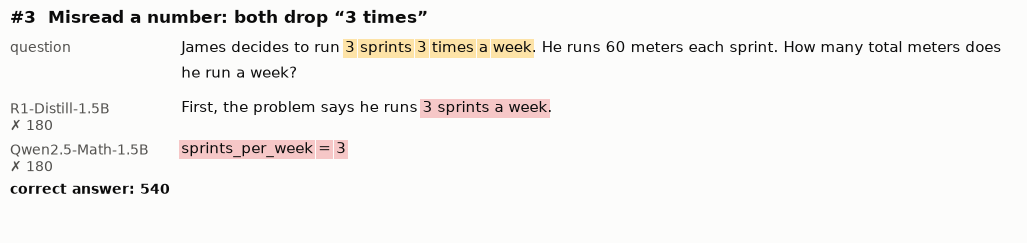

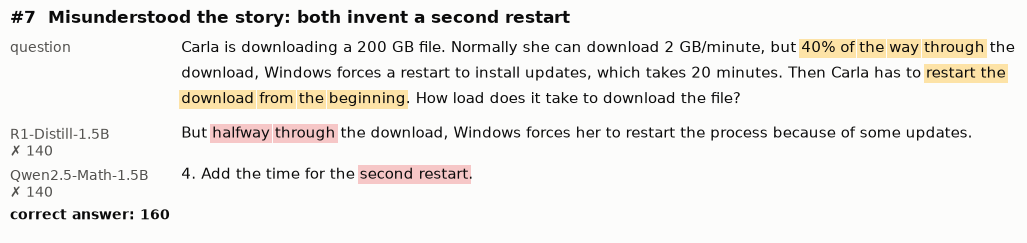

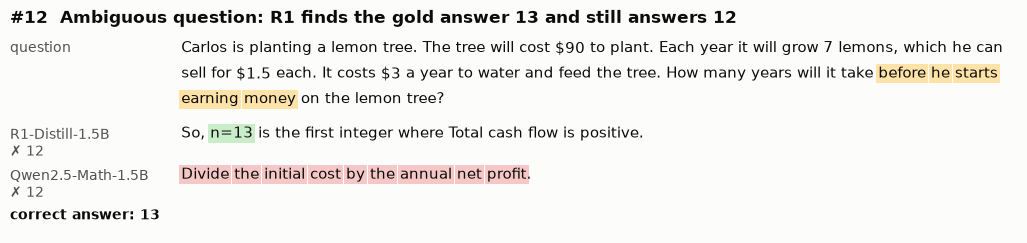

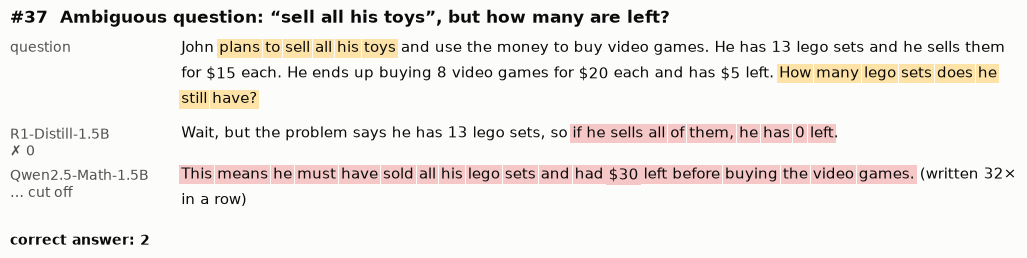

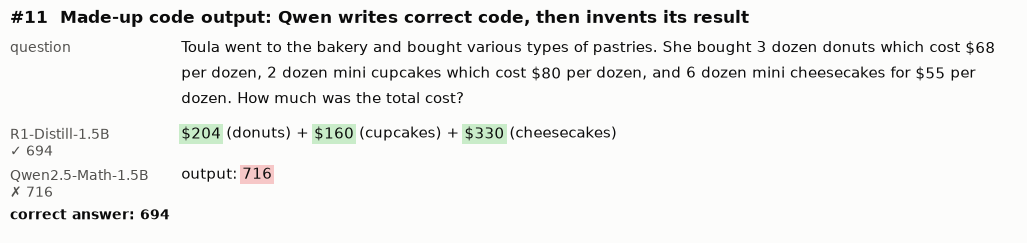

In [9]:
CASES = [
    dict(id=3, title="Misread a number: both drop “3 times”",
         key=["3 sprints 3 times a week"],
         quotes={R1: ("First, the problem says he runs 3 sprints a week.", [("3 sprints a week", MARK_BAD)]),
                 QWEN: ("sprints_per_week = 3", [("sprints_per_week = 3", MARK_BAD)])}),
    dict(id=7, title="Misunderstood the story: both invent a second restart",
         key=["40% of the way through", "restart the download from the beginning"],
         quotes={R1: ("But halfway through the download, Windows forces her to restart the process because of some updates.",
                      [("halfway through", MARK_BAD)]),
                 QWEN: ("4. Add the time for the second restart.", [("second restart", MARK_BAD)])}),
    dict(id=12, title="Ambiguous question: R1 finds the gold answer 13 and still answers 12",
         key=["before he starts earning money"],
         quotes={R1: ("So, n=13 is the first integer where Total cash flow is positive.", [("n=13", MARK_GOOD)]),
                 QWEN: ("Divide the initial cost by the annual net profit.",
                        [("Divide the initial cost by the annual net profit", MARK_BAD)])}),
    dict(id=37, title="Ambiguous question: “sell all his toys”, but how many are left?",
         key=["plans to sell all his toys", "How many lego sets does he still have?"],
         quotes={R1: ("Wait, but the problem says he has 13 lego sets, so if he sells all of them, he has 0 left.",
                      [("if he sells all of them, he has 0 left", MARK_BAD)]),
                 QWEN: ("This means he must have sold all his lego sets and had $30 left before buying the video games.",
                        [("This means he must have sold all his lego sets and had $30 left before buying the video games.", MARK_BAD)])}),
    dict(id=11, title="Made-up code output: Qwen writes correct code, then invents its result",
         key=[],
         quotes={R1: ("$204 (donuts) + $160 (cupcakes) + $330 (cheesecakes)", [("$204", MARK_GOOD), ("$160", MARK_GOOD), ("$330", MARK_GOOD)]),
                 QWEN: ("```output\n716", [("716", MARK_BAD)])}),
]


def segments(text, marks):
    # Split text into (piece, highlight colour or None) using the marked substrings
    spans = sorted((text.index(s), text.index(s) + len(s), c) for s, c in marks)
    out, pos = [], 0
    for a, b, c in spans:
        out += [(text[pos:a], None), (text[a:b], c)]
        pos = b
    return out + [(text[pos:], None)]


def draw_rich_text(ax, x, y, parts, width, fontsize=10.5, color=INK):
    # Draw word-wrapped text with highlighted words, in axes coordinates. Returns the y of the next line.
    renderer = ax.figure.canvas.get_renderer()
    to_axes = ax.transAxes.inverted()
    line = fontsize * 1.75 / 72 / (ax.get_window_extent().height / ax.figure.dpi)

    def width_of(t):
        bb = t.get_window_extent(renderer)
        return to_axes.transform((bb.x1, 0))[0] - to_axes.transform((bb.x0, 0))[0]

    probe = ax.text(0, 0, "a", fontsize=fontsize)
    space = width_of(probe) * 0.55
    probe.remove()
    # words with a flag "glued": no white space before it (e.g. "." right after a highlighted phrase)
    words, prev_ends_with_space = [], True
    for text, bg in parts:
        for m in re.finditer(r"\S+", text):
            glued = m.start() == 0 and not prev_ends_with_space and bool(words)
            words.append((m.group(0), bg, glued))
        if text:
            prev_ends_with_space = text[-1].isspace()
    cx, cy = x, y
    for word, bg, glued in words:
        if glued:
            cx -= space
        t = ax.text(cx, cy, word, transform=ax.transAxes, fontsize=fontsize, va="top", color=color,
                    bbox=dict(boxstyle="square,pad=0.15", fc=bg, ec="none") if bg else None)
        w = width_of(t)
        if cx + w > x + width and cx > x:
            cx, cy = x, cy - line
            t.set_position((cx, cy))
        cx += w + space
    return cy - line


def plot_case(case):
    pid = case["id"]
    question = problems.loc[pid, "question"]
    for s in case["key"]:
        assert s in question, s
    fig, ax = plt.subplots(figsize=(13, 2.9))
    ax.axis("off")
    fig.canvas.draw()
    ax.text(0, 1, f"#{pid}  {case['title']}", transform=ax.transAxes, fontsize=12.5, weight="bold", color=INK, va="top")
    ax.text(0, 0.86, "question", transform=ax.transAxes, fontsize=10, color=INK_MUTED, va="top")
    y = draw_rich_text(ax, 0.17, 0.86, segments(question, [(s, MARK_KEY) for s in case["key"]]), 0.83) - 0.04
    for model in [R1, QWEN]:
        quote, marks = case["quotes"][model]
        assert quote in outputs.loc[pid, model], f"quote not found in {model} output for #{pid}: {quote}"
        o = outcomes.loc[pid, model]
        ans = answers.loc[pid, model] if o in ("correct", "wrong") else o
        ax.text(0, y, f"{model}\n{SYMBOLS[o]} {ans}", transform=ax.transAxes, fontsize=10, color=INK_MUTED, va="top")
        repeats = outputs.loc[pid, model].count(quote)
        shown = quote.replace("```output\n", "output: ") + (f"   (written {repeats}× in a row)" if repeats > 3 else "")
        y = draw_rich_text(ax, 0.17, y, segments(shown, marks), 0.83) - 0.07
    ax.text(0, y, f"correct answer: {problems.loc[pid, 'gold']}", transform=ax.transAxes, fontsize=10, color=INK,
            va="top", weight="bold")
    plt.show()


for case in CASES:
    plot_case(case)

**Takeaways**
* In #3 and #7 the mistake is made **in the first sentence**, when the model restates the question, before any
  calculation. Everything after that is correct maths on the wrong problem, and R1's long thinking never questions it.
* #12 and #37 are arguably **badly worded questions** (#37 even contradicts itself). R1 actually considers the gold
  answer in #12, but picks the other reading.
* #11 shows the difference in *carrying out*: Qwen pretends to run code, R1 calculates in text.

Experiment B (section 6) tests the first two points: if we reword these questions clearly, do the models get them right?

## 4. Inside R1's thinking
R1 writes ~1,400 tokens of thinking per problem (median) against ~350 for Qwen. **What is all that text for?**

We search the thinking for the moments where the **correct answer is stated as a result** (e.g. `= 18`, `is 18`,
`total of 18`, not just any mention of the number), and for **hesitation words** (`wait`, `hmm`, `let me check`, …).
Positions are given in tokens (estimated from the character position).

In [10]:
HESITATION = re.compile(r"\b(wait|hmm|let me (?:double[- ])?check|let me verify|but let me)\b", re.IGNORECASE)


def stated_as_result(think, value):
    # Character positions where `value` is stated as the result of a step (commas removed from the text)
    pattern = r"(?:=|\bis|\bbe|\bget|\btotal of|\bequals)\s*\\?\$?\s*" + re.escape(value) + r"(?![\d]|\.\d)"
    return [m.end() for m in re.finditer(pattern, think)]


def number_str(answer):
    # '\\$1,234' -> '1234', '234.0' -> '234'; None if not a number
    if answer is None or (not isinstance(answer, str) and pd.isna(answer)):
        return None
    nums = re.findall(r"-?\d+(?:\.\d+)?", str(answer).replace(",", ""))
    if not nums:
        return None
    v = float(nums[-1])
    return str(int(v)) if v.is_integer() else str(v)


rows = []
for pid in problems.index:
    text = outputs.loc[pid, R1]
    think = thinking(text).replace(",", "")
    think_tokens = tokens.loc[pid, R1] * len(thinking(text)) / len(text)
    to_tok = lambda char_pos: char_pos / len(think) * think_tokens
    gold_pos = stated_as_result(think, problems.loc[pid, "gold"])
    final = number_str(answers.loc[pid, R1])
    wrong_pos = stated_as_result(think, final) if final and final != problems.loc[pid, "gold"] else []
    # If the correct number also appears in the question (e.g. "20 chickens"), it can be "stated as a result"
    # by coincidence ("20 chickens * 1 cup = 20 cups"), so its first position is not reliable.
    in_question = re.search(r"(?<![\d.])" + re.escape(problems.loc[pid, "gold"]) + r"(?![\d]|\.\d)",
                            problems.loc[pid, "question"].replace(",", "")) is not None
    rows.append(dict(id=pid, outcome=outcomes.loc[pid, R1], think_tokens=think_tokens, gold_in_question=in_question,
                     gold_first=to_tok(gold_pos[0]) if gold_pos else np.nan, gold_count=len(gold_pos),
                     wrong_first=to_tok(wrong_pos[0]) if wrong_pos else np.nan,
                     hesitations=[to_tok(m.start()) for m in HESITATION.finditer(think)]))
r1_think = pd.DataFrame(rows).set_index("id")
r1_think["share_after"] = 1 - r1_think["gold_first"] / r1_think["think_tokens"]
print("Correct number also in the question (position unreliable, left out of the statistics):",
      [f"#{i}" for i in r1_think.index[r1_think.gold_in_question]])

ok = r1_think[(r1_think.outcome == "correct") & ~r1_think.gold_in_question]
print(f"Correct answers ({len(ok)}): the correct result is first stated after a median of "
      f"{(1 - ok.share_after).median():.0%} of the thinking ({ok.gold_first.median():.0f} tokens); "
      f"the remaining {ok.share_after.median():.0%} ({(ok.think_tokens - ok.gold_first).median():.0f} tokens) come after it.")
print(f"It is stated as a result {ok.gold_count.median():.0f} times (median) before R1 stops thinking.")

Correct number also in the question (position unreliable, left out of the statistics): ['#4', '#20', '#31', '#44']
Correct answers (40): the correct result is first stated after a median of 40% of the thinking (417 tokens); the remaining 60% (664 tokens) come after it.
It is stated as a result 6 times (median) before R1 stops thinking.


### 4.1 Answer timeline
One bar per problem = R1's thinking, from the first token (left) to `</think>` (right end).
**Dark blue** = before the correct result first appears, **light blue** = after it (checking, repeating, doubting).
A grey bar means the correct result never appears.

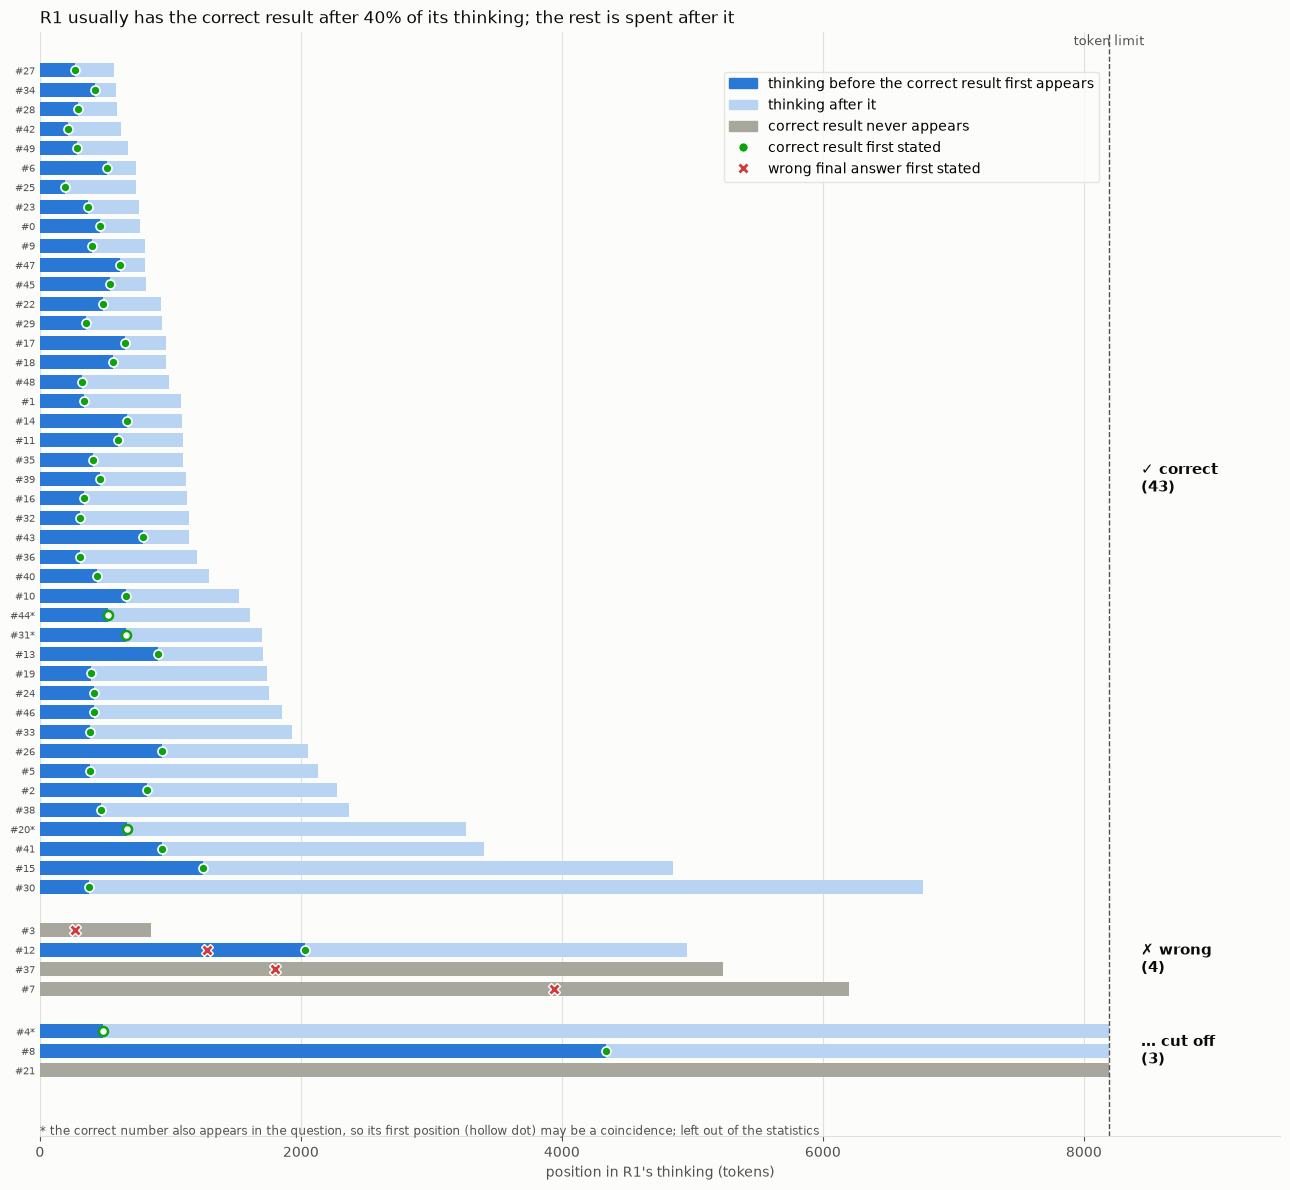

In [11]:
OUTCOME_ORDER = ["correct", "wrong", "cut off"]
data = r1_think.copy()
data["rank"] = data["outcome"].map(OUTCOME_ORDER.index)
data = data.sort_values(["rank", "think_tokens"])

fig, ax = plt.subplots(figsize=(13, 12))
y, yticks, ylabels, group_y = 0, [], [], {}
for o in OUTCOME_ORDER:
    part = data[data.outcome == o]
    group_y[o] = (y, y + len(part) - 1, len(part))
    for pid, r in part.iterrows():
        h = 0.72
        if np.isnan(r.gold_first):
            ax.barh(y, r.think_tokens, height=h, color=COLORS["cut off"])
        else:
            ax.barh(y, r.gold_first, height=h, color=BLUE)
            ax.barh(y, r.think_tokens - r.gold_first, left=r.gold_first, height=h, color=BLUE_LIGHT)
            if r.gold_in_question:   # hollow marker: position may be a coincidence
                ax.plot(r.gold_first, y, marker="o", ms=6.5, color=SURFACE, mec=COLORS["correct"], mew=1.8, zorder=3)
            else:
                ax.plot(r.gold_first, y, marker="o", ms=6.5, color=COLORS["correct"], mec="white", mew=1.2, zorder=3)
        if not np.isnan(r.wrong_first):
            ax.plot(r.wrong_first, y, marker="X", ms=8, color=COLORS["wrong"], mec="white", mew=1.0, zorder=3)
        yticks.append(y)
        ylabels.append(f"#{pid}" + ("*" if r.gold_in_question else ""))
        y += 1
    y += 1.2   # gap between groups

LIMIT = 8192
ax.axvline(LIMIT, color=INK_MUTED, lw=1, ls="--")
ax.text(LIMIT, -1.3, "token limit", ha="center", fontsize=9, color=INK_MUTED)
for o, (a, b, n) in group_y.items():
    ax.text(LIMIT * 1.03, (a + b) / 2, f"{SYMBOLS[o]} {o}\n({n})", va="center", fontsize=10.5, color=INK, weight="bold")
ax.text(0, y + 0.6, "* the correct number also appears in the question, so its first position (hollow dot) may be a "
        "coincidence; left out of the statistics", fontsize=8.5, color=INK_MUTED, va="top")

ax.set_yticks(yticks, ylabels, fontsize=7.5)
ax.set_ylim(y + 1.2, -2)
ax.set_xlim(0, LIMIT * 1.16)
ax.set_xlabel("position in R1's thinking (tokens)")
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.legend(handles=[Patch(color=BLUE, label="thinking before the correct result first appears"),
                   Patch(color=BLUE_LIGHT, label="thinking after it"),
                   Patch(color=COLORS["cut off"], label="correct result never appears"),
                   Line2D([], [], marker="o", ls="", color=COLORS["correct"], mec="white", ms=7, label="correct result first stated"),
                   Line2D([], [], marker="X", ls="", color=COLORS["wrong"], mec="white", ms=8, label="wrong final answer first stated")],
          loc="upper right", bbox_to_anchor=(0.86, 0.97), frameon=True, facecolor=SURFACE, edgecolor=GRID)
share = 1 - ok.share_after.median()
ax.set_title(f"R1 usually has the correct result after {share:.0%} of its thinking; the rest is spent after it",
             loc="left", fontsize=12.5, color=INK)
plt.tight_layout()
plt.show()

### 4.2 Value lanes: what does R1 compute, and how often?
Every number R1 writes after an `=` sign, at its position in the thinking. Each **row is one value** (the 8 most
frequent, plus the correct answer and R1's final answer); each dot is one time R1 computed it.
A row of dots across the whole bar = R1 computes the same value **again and again**.

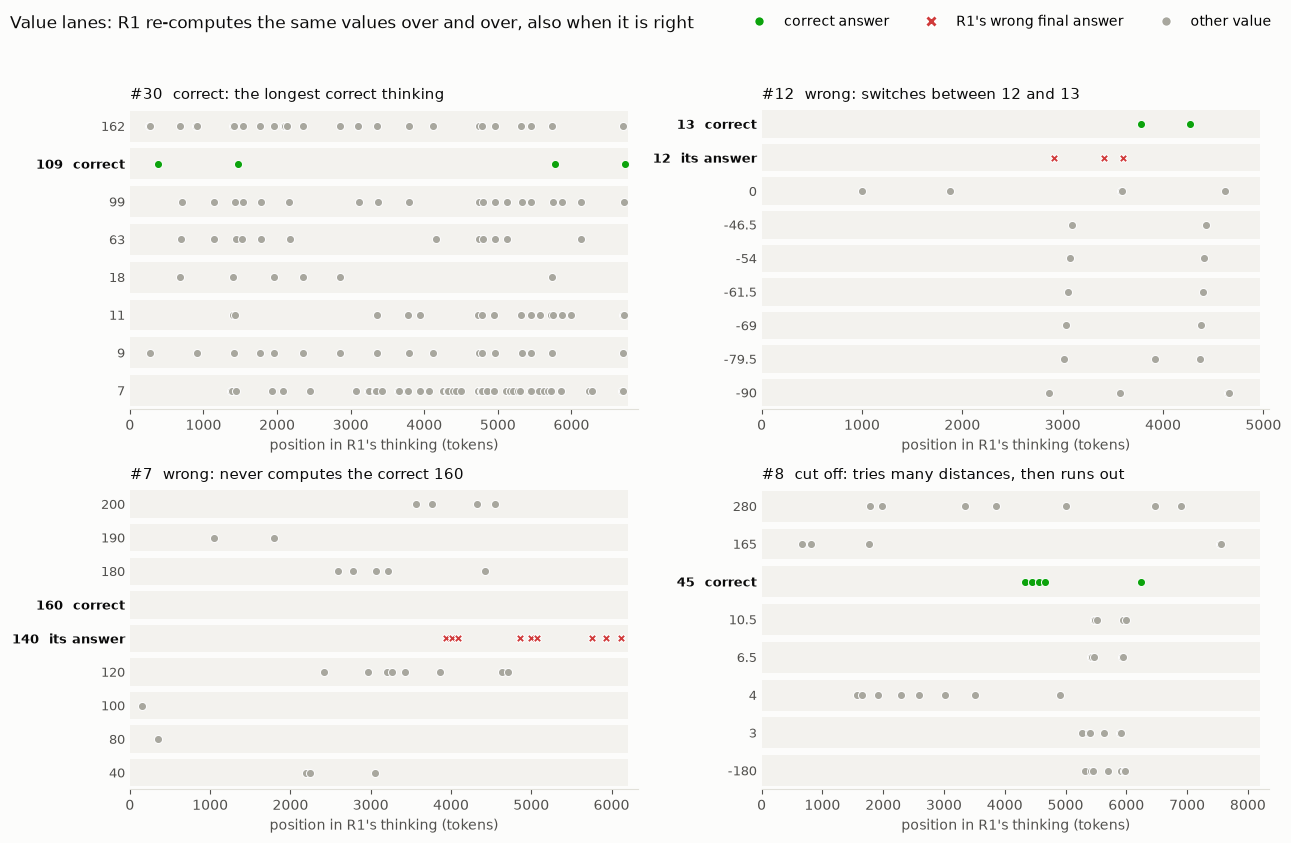

In [12]:
RESULT = re.compile(r"=\s*\\?\$?\s*(-?\d+(?:\.\d+)?)")


def computed_values(pid):
    # (position in tokens, value as string) for every number written after "=" in R1's thinking
    text = outputs.loc[pid, R1]
    think = thinking(text).replace(",", "")
    think_tokens = tokens.loc[pid, R1] * len(thinking(text)) / len(text)
    return [(m.start() / len(think) * think_tokens, number_str(m.group(1))) for m in RESULT.finditer(think)], think_tokens


LANE_IDS = [(ok.think_tokens.idxmax(), "correct: the longest correct thinking"),
            (12, "wrong: switches between 12 and 13"),
            (7, "wrong: never computes the correct 160"),
            (8, "cut off: tries many distances, then runs out")]

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5))
for ax, (pid, subtitle) in zip(axes.flat, LANE_IDS):
    values, think_tokens = computed_values(pid)
    gold, final = problems.loc[pid, "gold"], number_str(answers.loc[pid, R1])
    counts = pd.Series([v for _, v in values]).value_counts()
    lanes = list(counts.index[:8])
    for must in [gold, final]:
        if must and must not in lanes:
            lanes.append(must)
    lanes = sorted(lanes, key=float, reverse=True)
    ax.barh(range(len(lanes)), think_tokens, height=0.82, color="#f3f2ee", zorder=0)   # one track per value
    for k, v in enumerate(lanes):
        xs = [p for p, val in values if val == v]
        color = COLORS["correct"] if v == gold else COLORS["wrong"] if v == final else COLORS["cut off"]
        ax.scatter(xs, [k] * len(xs), s=34, color=color, ec="white", lw=0.7, zorder=3,
                   marker="X" if (v == final and v != gold) else "o")
    labels = [v + ("  correct" if v == gold else "  its answer" if v == final else "") for v in lanes]
    ax.set_yticks(range(len(lanes)), labels, fontsize=9)
    for t, v in zip(ax.get_yticklabels(), lanes):
        t.set_color(INK if v in (gold, final) else INK_MUTED)
        t.set_weight("bold" if v in (gold, final) else "normal")
    ax.set_ylim(len(lanes) - 0.5, -0.5)
    ax.set_xlim(0, max(think_tokens, 100) * 1.02)
    ax.set_title(f"#{pid}  {subtitle}", loc="left", fontsize=10.5, color=INK)
    ax.set_xlabel("position in R1's thinking (tokens)")
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=COLORS["correct"], mec="white", ms=7, label="correct answer"),
                    Line2D([], [], marker="X", ls="", color=COLORS["wrong"], mec="white", ms=8, label="R1's wrong final answer"),
                    Line2D([], [], marker="o", ls="", color=COLORS["cut off"], mec="white", ms=7, label="other value")],
           loc="upper right", bbox_to_anchor=(0.99, 0.995), ncol=3, frameon=False)
fig.suptitle("Value lanes: R1 re-computes the same values over and over, also when it is right",
             x=0.01, ha="left", fontsize=12.5, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

### 4.3 Hesitation: does doubting help?
Hesitation words (`wait`, `hmm`, `let me check`, …) per 1,000 tokens, one dot per problem.

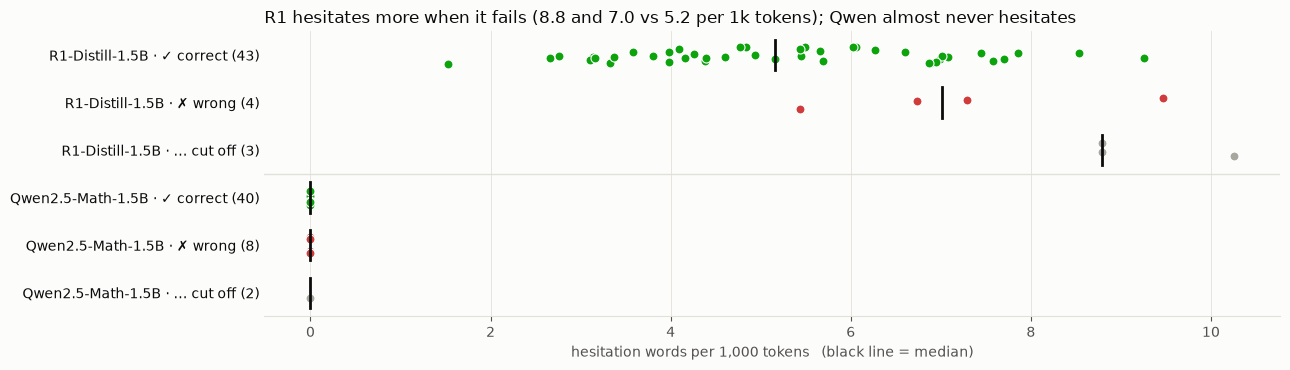

In [13]:
rng = np.random.default_rng(0)
hes = []
for pid in problems.index:
    for model in [R1, QWEN]:
        text = outputs.loc[pid, model]
        hes.append(dict(model=model, id=pid, outcome=outcomes.loc[pid, model],
                        per_1k=len(HESITATION.findall(text)) / tokens.loc[pid, model] * 1000))
hes = pd.DataFrame(hes)

fig, ax = plt.subplots(figsize=(13, 3.8))
ylabels = []
for k, (model, o) in enumerate([(m, o) for m in [R1, QWEN] for o in OUTCOME_ORDER]):
    d = hes[(hes.model == model) & (hes.outcome == o)]
    ylabels.append(f"{model} · {SYMBOLS[o]} {o} ({len(d)})")
    if len(d):
        ax.scatter(d.per_1k, k + rng.uniform(-0.18, 0.18, len(d)), s=42, color=COLORS[o], ec="white", lw=0.8, zorder=3)
        ax.plot([d.per_1k.median()] * 2, [k - 0.32, k + 0.32], color=INK, lw=2, zorder=4)
ax.axhline(2.5, color=GRID, lw=1)
ax.set_yticks(range(len(ylabels)), ylabels, color=INK)
ax.set_ylim(len(ylabels) - 0.5, -0.5)
ax.set_xlabel("hesitation words per 1,000 tokens   (black line = median)")
ax.grid(axis="x", color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
med = hes[hes.model == R1].groupby("outcome").per_1k.median()
ax.set_title(f"R1 hesitates more when it fails ({med['cut off']:.1f} and {med['wrong']:.1f} vs {med['correct']:.1f} per 1k tokens); "
             "Qwen almost never hesitates", loc="left", fontsize=12, color=INK)
plt.tight_layout()
plt.show()

**Takeaways (section 4)**
* For correct answers, R1 states the correct result early and then **keeps going for most of its thinking**:
  re-checking, re-deriving, and repeating the same result several times.
* When R1 fails, the correct result sometimes *does* appear (#12, #8), but R1 does not settle on it; the value lanes
  show it **switching between a few candidates** instead of converging.
* Doubt is not a sign of good reasoning here: R1 hesitates **more** on the problems it gets wrong.

This is descriptive, so it cannot tell us if the "checking" part is useful. Experiment A tests that directly.

## 5. Experiment A: early answering, how much of the thinking does R1 need?
We take R1's saved thinking for each of the 50 problems, **cut it off** after 0%, 10%, 25%, 50%, 75% or 100% of its
tokens, close the thinking and **force an answer** right away:

`<question> <first x% of the thinking> </think> The final answer is \boxed{` → the model completes the number (greedy).

If the forced answer is already correct at 50%, the second half of the thinking was not needed for *this* answer.
(Method after Lanham et al., 2023, *Measuring Faithfulness in Chain-of-Thought Reasoning*.)

Results are saved to `nb03_early_answering.jsonl` in the run folder; if the file is complete, nothing is re-run.

In [14]:
import gc

try:
    import torch
    from transformers import (AutoModelForCausalLM, AutoTokenizer, StoppingCriteria, StoppingCriteriaList,
                              set_seed)
    DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else None
except ImportError:
    torch, DEVICE = None, None
print("Device for the experiments:", DEVICE or "none (saved experiment results are loaded, nothing is re-run)")

R1_NAME, QWEN_NAME = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B", "Qwen/Qwen2.5-Math-1.5B"
INSTRUCTION = "Please reason step by step, and put your final answer within \\boxed{}."
SEED = 42


def load_jsonl(path):
    if not Path(path).exists():
        return []
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]


def append_jsonl(path, rows):
    with open(path, "a", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")


def load_model(name):
    tok = AutoTokenizer.from_pretrained(name)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16).to(DEVICE).eval()
    return model, tok


def free_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def build_prompt(tok, question, chat_template):
    text = question + "\n" + INSTRUCTION
    if not chat_template:
        return text + "\n"
    return tok.apply_chat_template([{"role": "user", "content": text}], tokenize=False, add_generation_prompt=True)


def boxed_answers(text):
    found = []
    for m in re.finditer(r"\\boxed\{", text):
        depth = 1
        for j in range(m.end(), len(text)):
            depth += {"{": 1, "}": -1}.get(text[j], 0)
            if depth == 0:
                if text[m.end():j].strip():
                    found.append(text[m.end():j].strip())
                break
    return found


def is_correct(answer, gold):
    value = number_str(answer)
    return value is not None and math.isclose(float(value), float(gold), abs_tol=1e-6)

Device for the experiments: none (saved experiment results are loaded, nothing is re-run)


In [15]:
FRACTIONS = [0, 0.1, 0.25, 0.5, 0.75, 1.0]
EARLY_PATH = RESULTS_DIR / "nb03_early_answering.jsonl"
RUN_EARLY_ANSWERING = True     # set to False to never start the model (only load saved results)

done = {(r["id"], r["fraction"]) for r in load_jsonl(EARLY_PATH)}
todo = [pid for pid in problems.index if any((int(pid), f) not in done for f in FRACTIONS)]
print(f"Early answering: {len(problems) - len(todo)}/{len(problems)} problems done")

if todo and RUN_EARLY_ANSWERING and DEVICE:
    model, tok = load_model(R1_NAME)
    suffix = tok("\n</think>\n\nThe final answer is \\boxed{", add_special_tokens=False).input_ids
    for n, pid in enumerate(todo):
        prompt = tok(build_prompt(tok, problems.loc[pid, "question"], True), add_special_tokens=False).input_ids
        think = tok(thinking(outputs.loc[pid, R1]), add_special_tokens=False).input_ids
        rows = []
        for f in FRACTIONS:
            if (int(pid), f) in done:
                continue
            kept = think[:round(f * len(think))]
            ids = torch.tensor([prompt + kept + suffix], device=DEVICE)
            with torch.no_grad():
                out = model.generate(ids, attention_mask=torch.ones_like(ids), max_new_tokens=16, do_sample=False,
                                     temperature=None, top_p=None, top_k=None, pad_token_id=tok.pad_token_id)
            completion = tok.decode(out[0, ids.shape[1]:], skip_special_tokens=True)
            answer = completion.split("}")[0].strip()
            rows.append(dict(id=int(pid), fraction=f, kept_tokens=len(kept), think_tokens=len(think),
                             completion=completion, answer=answer, correct=is_correct(answer, problems.loc[pid, "gold"])))
        append_jsonl(EARLY_PATH, rows)
        print(f"  {n + 1}/{len(todo)}  #{pid}: " + " ".join("✓" if r["correct"] else "✗" for r in rows))
    del model, tok
    free_memory()

early = pd.DataFrame(load_jsonl(EARLY_PATH))
if len(early):
    display(early.groupby("fraction").correct.agg(accuracy="mean", correct="sum", problems="count"))

Early answering: 50/50 problems done


,accuracy,correct,problems
fraction,,,
0.00,0.12,6,50
0.10,0.20,10,50
0.25,0.36,18,50
0.50,0.74,37,50
0.75,0.90,45,50
1.00,0.90,45,50


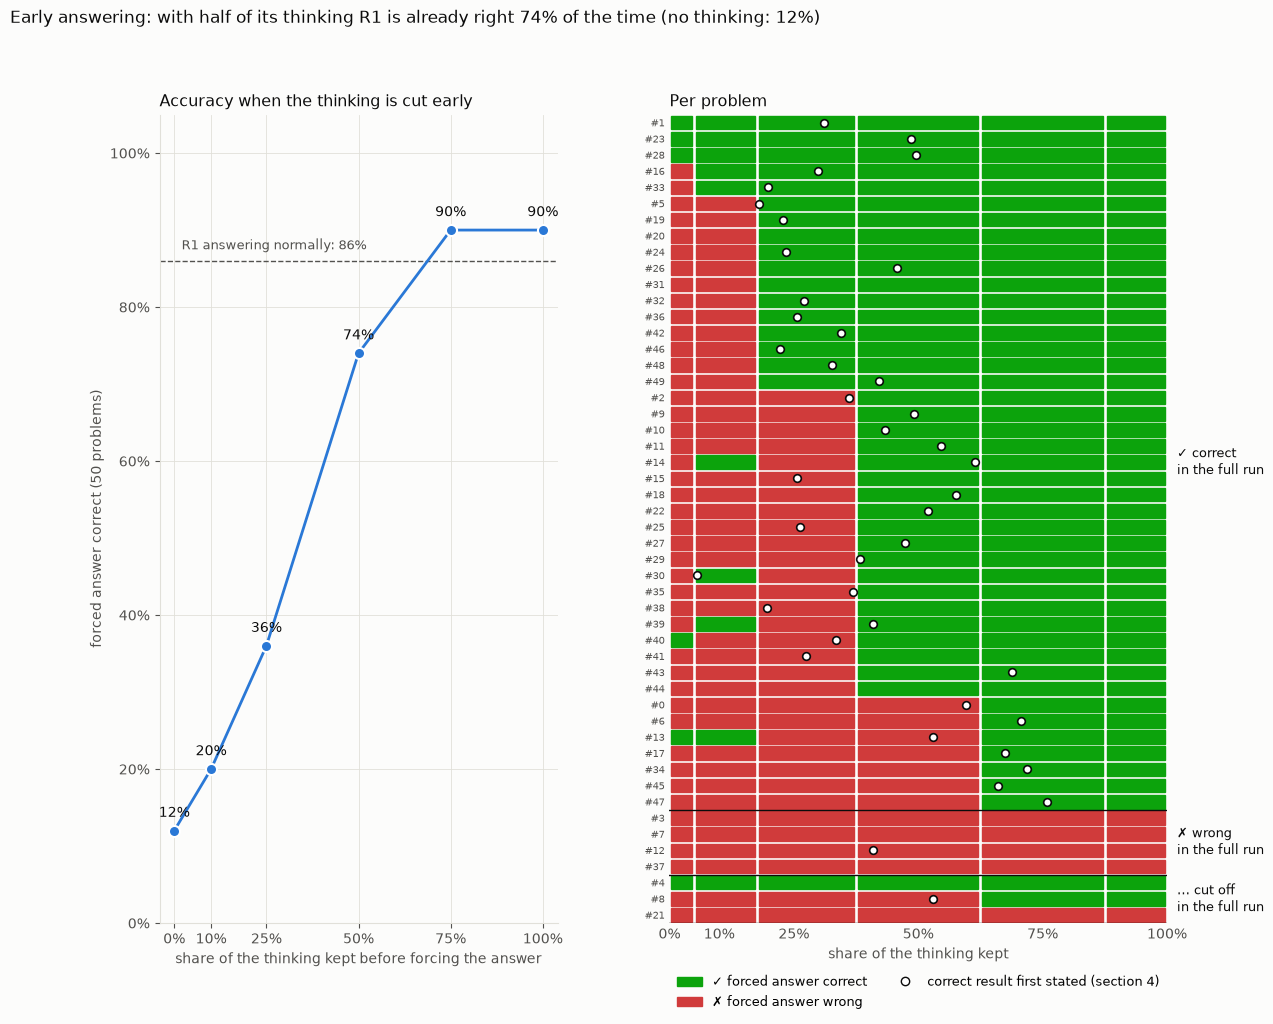

In [16]:
if len(early) == 0:
    print("No early-answering results yet: run the cell above on a GPU.")
else:
    piv = early.pivot(index="id", columns="fraction", values="correct").astype(bool)

    def locks_in(row):
        # first fraction from which the forced answer stays correct (2 = never)
        for f in FRACTIONS:
            if row.loc[f:].all():
                return f
        return 2.0

    lock = piv.apply(locks_in, axis=1)
    order_e = sorted(piv.index, key=lambda i: (OUTCOME_ORDER.index(outcomes.loc[i, R1]), lock[i], i))
    edges = [0] + [(a + b) / 2 for a, b in zip(FRACTIONS, FRACTIONS[1:])] + [1.0]

    fig = plt.figure(figsize=(13, 10.5))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.25], wspace=0.25)

    # Left: accuracy curve
    ax = fig.add_subplot(gs[0])
    acc = piv.mean()
    ax.plot(FRACTIONS, acc.values, color=BLUE, lw=2, marker="o", ms=8, mec="white", mew=1.5, zorder=3)
    for f, a in acc.items():
        ax.annotate(f"{a:.0%}", (f, a), textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=INK)
    full = (outcomes[R1] == "correct").mean()
    ax.axhline(full, color=INK_MUTED, ls="--", lw=1)
    ax.text(0.02, full + 0.015, f"R1 answering normally: {full:.0%}", fontsize=9, color=INK_MUTED)
    ax.set_xticks(FRACTIONS, [f"{f:.0%}" for f in FRACTIONS])
    ax.set_xlim(-0.04, 1.04)
    ax.set_ylim(0, 1.05)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of the thinking kept before forcing the answer")
    ax.set_ylabel("forced answer correct (50 problems)")
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title("Accuracy when the thinking is cut early", loc="left", fontsize=11.5, color=INK)

    # Right: per problem
    ax = fig.add_subplot(gs[1])
    for yy, pid in enumerate(order_e):
        for k, f in enumerate(FRACTIONS):
            c = COLORS["correct"] if piv.loc[pid, f] else COLORS["wrong"]
            ax.add_patch(plt.Rectangle((edges[k] + 0.004, yy + 0.08), edges[k + 1] - edges[k] - 0.008, 0.84, color=c))
        g = r1_think.loc[pid, "gold_first"] / r1_think.loc[pid, "think_tokens"]
        if not np.isnan(g) and not r1_think.loc[pid, "gold_in_question"]:
            ax.plot(g, yy + 0.5, marker="o", ms=5.5, color="white", mec=INK, mew=1.2, zorder=3)
    bounds = np.cumsum([0] + [int((outcomes.loc[order_e, R1] == o).sum()) for o in OUTCOME_ORDER])
    for o, a, b in zip(OUTCOME_ORDER, bounds, bounds[1:]):
        if b > a:
            ax.text(1.02, (a + b) / 2, f"{SYMBOLS[o]} {o}\nin the full run", va="center", fontsize=9.5, color=INK)
            ax.axhline(b, color=INK, lw=1)
    ax.set_xlim(0, 1)
    ax.set_ylim(len(order_e), 0)
    ax.set_xticks(FRACTIONS, [f"{f:.0%}" for f in FRACTIONS])
    ax.set_yticks(np.arange(len(order_e)) + 0.5, [f"#{i}" for i in order_e], fontsize=7)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_xlabel("share of the thinking kept")
    ax.legend(handles=[Patch(color=COLORS["correct"], label="✓ forced answer correct"),
                       Patch(color=COLORS["wrong"], label="✗ forced answer wrong"),
                       Line2D([], [], marker="o", ls="", color="white", mec=INK, ms=6, label="correct result first stated (section 4)")],
              loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=2, frameon=False, fontsize=9)
    ax.set_title("Per problem", loc="left", fontsize=11.5, color=INK)

    fig.suptitle(f"Early answering: with half of its thinking R1 is already right {acc[0.5]:.0%} of the time "
                 f"(no thinking: {acc[0]:.0%})", x=0.01, ha="left", fontsize=12.5, color=INK)
    plt.show()

**Takeaways (section 5)**
* **The thinking does real work.** Forced to answer with no thinking at all, R1 is right on only 6 of 50 problems (12%).
  It cannot solve these problems "in its head".
* **R1 needs about three quarters of its thinking.** Accuracy climbs steeply from 25% to 75% of the thinking
  (36% → 74% → 90%); **the last quarter adds nothing** (90% → 90%). That last part is checking that does not change the answer.
* **The visible reasoning matches the answer.** In the per-problem plot, the forced answer turns correct (red → green)
  around the point where the correct result first appears in the text (white dots, section 4). What R1 writes is what it
  then answers, so here the chain of thought is a faithful record, not decoration.
* **R1 sometimes knows the answer and does not stop.** With its full thinking, the forced answer is right on 45 problems,
  2 more than in the normal run: in #8 R1 had the correct 45 after 75% of its thinking, but kept going and was cut off.
  (#4 is correct even with no thinking because its answer, 20, is the number of chickens in the question: a lucky guess.)

## 6. Experiment B: are the shared mistakes caused by the wording?
For the five problems where the models misread the question or where the question is ambiguous, we wrote a
**clearer version with the same correct answer** and ran both models on both versions, with the same settings as
Notebook 01. R1 samples (temperature 0.6), so it is run **4 times** per version; Qwen is greedy, so once is enough.

In [17]:
REWORDED = {
    3:  "James runs 3 sprints per session, and he does 3 sessions every week. Each sprint is 60 meters. "
        "How many total meters does he run a week?",
    4:  "Every day, Wendi gives each of her chickens three cups of feed in total, split over three meals. "
        "In the morning, she gives her flock 15 cups of feed. In the afternoon, she gives them another 25 cups. "
        "She has 20 chickens. How many cups of feed does she need to give them in the final meal of the day?",
    7:  "Carla is downloading a 200 GB file at 2 GB/minute. When 40% of the file is downloaded, Windows restarts the "
        "computer, which takes 20 minutes. After the restart she downloads the whole file again from the beginning, "
        "without any interruption. How many minutes does it take in total, from the start until the download is finished?",
    12: "Carlos is planting a lemon tree. The tree costs $90 to plant. Each year it grows 7 lemons, which he sells for "
        "$1.5 each. It costs $3 a year to water and feed the tree. After how many years will he have earned more "
        "money from the tree than he has spent on it?",
    37: "John has 13 lego sets. He sells some of them for $15 each and uses all of that money to buy 8 video games "
        "for $20 each, after which he has $5 left. How many lego sets does he still have?",
}
N_SAMPLES_R1 = 4
REWORD_PATH = RESULTS_DIR / "nb03_rewording.jsonl"
RUN_REWORDING = True
MODEL_CFG = {R1:   dict(name=R1_NAME,   chat_template=True,  sampling=True,  max_new_tokens=8192, n=N_SAMPLES_R1, stop_after_answer=False),
             QWEN: dict(name=QWEN_NAME, chat_template=False, sampling=False, max_new_tokens=2048, n=1, stop_after_answer=True)}

pd.DataFrame({"original": problems.loc[list(REWORDED), "question"], "reworded": pd.Series(REWORDED),
              "gold": problems.loc[list(REWORDED), "gold"]})

,original,reworded,gold
3,James decides to run 3 sprints 3 times a week. He runs 60 meters each sprint. How many total meters does he run a ...,"James runs 3 sprints per session, and he does 3 sessions every week. Each sprint is 60 meters. How many total meters...",540
4,"Every day, Wendi feeds each of her chickens three cups of mixed chicken feed, containing seeds, mealworms and vegeta...","Every day, Wendi gives each of her chickens three cups of feed in total, split over three meals. In the morning, she...",20
7,"Carla is downloading a 200 GB file. Normally she can download 2 GB/minute, but 40% of the way through the download, ...","Carla is downloading a 200 GB file at 2 GB/minute. When 40% of the file is downloaded, Windows restarts the computer...",160
12,"Carlos is planting a lemon tree. The tree will cost $90 to plant. Each year it will grow 7 lemons, which he can sell...","Carlos is planting a lemon tree. The tree costs $90 to plant. Each year it grows 7 lemons, which he sells for $1.5 e...",13
37,John plans to sell all his toys and use the money to buy video games. He has 13 lego sets and he sells them for $15 ...,John has 13 lego sets. He sells some of them for $15 each and uses all of that money to buy 8 video games for $20 ea...,2


In [18]:
if torch is not None:
    class StopAfterAnswer(StoppingCriteria):
        # Stops each sequence once it contains a \boxed{...} answer (Qwen base model, as in Notebook 01)
        def __init__(self, tok, prompt_length):
            self.tok, self.prompt_length = tok, prompt_length

        def __call__(self, input_ids, scores, **kwargs):
            texts = self.tok.batch_decode(input_ids[:, self.prompt_length:], skip_special_tokens=True)
            return torch.tensor([bool(boxed_answers(t)) for t in texts], device=input_ids.device)


def generate(model, tok, questions, cfg):
    # Same decoding as Notebook 01. Returns (text, n_tokens, finished) per question.
    prompts = [build_prompt(tok, q, cfg["chat_template"]) for q in questions]
    inputs = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
    plen = inputs["input_ids"].shape[1]
    stop_ids = [tok.eos_token_id]
    im_end = tok.convert_tokens_to_ids("<|im_end|>")
    if isinstance(im_end, int) and im_end != tok.unk_token_id:
        stop_ids.append(im_end)
    decoding = (dict(do_sample=True, temperature=0.6, top_p=0.95) if cfg["sampling"]
                else dict(do_sample=False, temperature=None, top_p=None, top_k=None))
    criteria = StoppingCriteriaList([StopAfterAnswer(tok, plen)] if cfg["stop_after_answer"] else [])
    with torch.no_grad():
        out = model.generate(**inputs, **decoding, max_new_tokens=cfg["max_new_tokens"], pad_token_id=tok.pad_token_id,
                             eos_token_id=stop_ids, stopping_criteria=criteria)
    res = []
    for seq in out[:, plen:].tolist():
        end = next((k for k, t in enumerate(seq) if t in stop_ids), None)
        n = end if end is not None else len(seq)
        text = tok.decode(seq[:n], skip_special_tokens=True)
        finished = end is not None or (cfg["stop_after_answer"] and bool(boxed_answers(text))) or n < cfg["max_new_tokens"]
        res.append((text, n, finished))
    return res


def final_answer(text, thinks):
    if thinks:
        if "</think>" not in text:
            return None
        boxes = boxed_answers(text.split("</think>")[-1])
        return boxes[-1] if boxes else None
    boxes = boxed_answers(text)
    return boxes[0] if boxes else None


done = {(r["model"], r["id"]) for r in load_jsonl(REWORD_PATH)}
for model_label, cfg in MODEL_CFG.items():
    todo = [pid for pid in REWORDED if (model_label, pid) not in done]
    print(f"Rewording, {model_label}: {len(REWORDED) - len(todo)}/{len(REWORDED)} problems done")
    if not (todo and RUN_REWORDING and DEVICE):
        continue
    model, tok = load_model(cfg["name"])
    for pid in todo:   # one batch per problem: n samples of the original + n of the reworded question
        set_seed(SEED + int(pid))
        versions = [("original", problems.loc[pid, "question"])] * cfg["n"] + [("reworded", REWORDED[pid])] * cfg["n"]
        outs = generate(model, tok, [q for _, q in versions], cfg)
        rows = []
        for k, ((wording, q), (text, n, finished)) in enumerate(zip(versions, outs)):
            ans = final_answer(text, thinks=model_label == R1)
            rows.append(dict(model=model_label, id=int(pid), wording=wording, sample=k % cfg["n"], output=text,
                             answer=ans, correct=is_correct(ans, problems.loc[pid, "gold"]), n_tokens=n, finished=finished))
        append_jsonl(REWORD_PATH, rows)
        print(f"  #{pid}: " + " ".join(f"{r['wording'][:4]}:{'✓' if r['correct'] else ('…' if not r['finished'] else '✗')}"
                                       for r in rows))
    del model, tok
    free_memory()

Rewording, R1-Distill-1.5B: 5/5 problems done
Rewording, Qwen2.5-Math-1.5B: 5/5 problems done


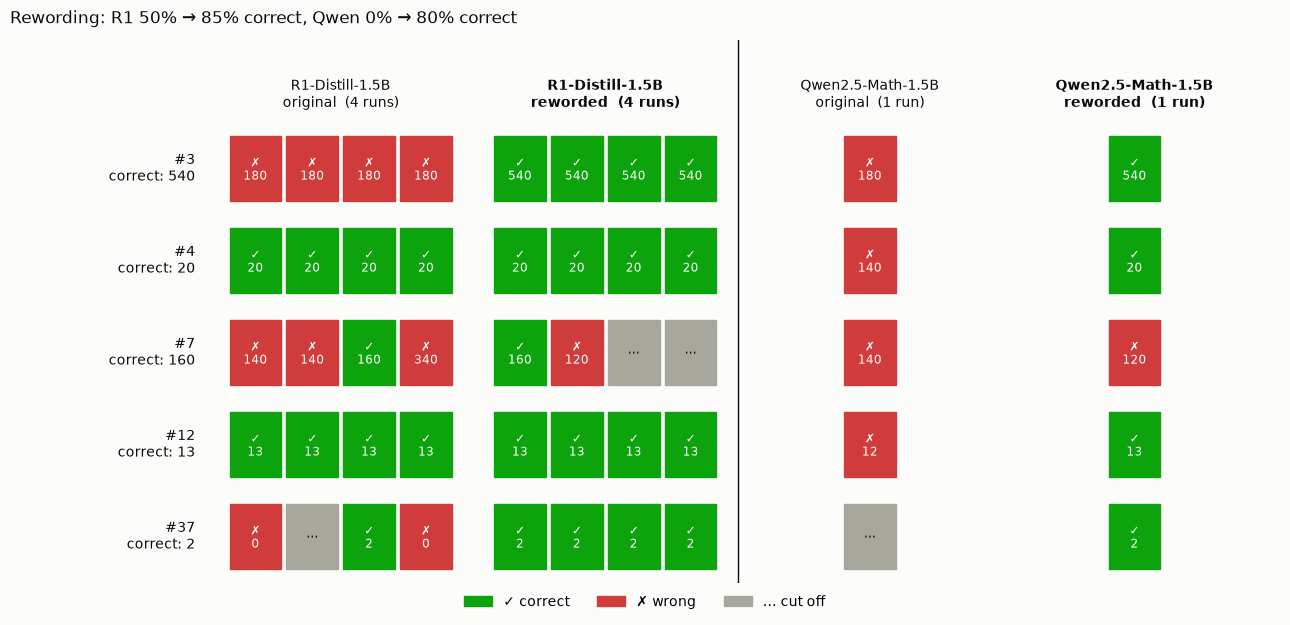

In [19]:
reword = pd.DataFrame(load_jsonl(REWORD_PATH))
if len(reword) == 0:
    print("No rewording results yet: run the cell above on a GPU.")
else:
    reword["outcome"] = reword.apply(lambda r: "cut off" if not r["finished"] else
                                     ("no answer" if r["answer"] is None else ("correct" if r["correct"] else "wrong")), axis=1)
    COLS = [(R1, "original"), (R1, "reworded"), (QWEN, "original"), (QWEN, "reworded")]
    pids = list(REWORDED)

    fig, ax = plt.subplots(figsize=(13, 0.95 * len(pids) + 1.6))
    for yy, pid in enumerate(pids):
        for k, (m, w) in enumerate(COLS):
            d = reword[(reword.model == m) & (reword.id == pid) & (reword.wording == w)].sort_values("sample")
            cw = 0.86 / N_SAMPLES_R1
            x0 = k + 0.07 if len(d) > 1 else k + 0.5 - cw / 2   # a single run is centred in its column
            for s, (_, r) in enumerate(d.iterrows()):
                o = r["outcome"]
                ax.add_patch(plt.Rectangle((x0 + s * cw + 0.01, yy + 0.15), cw - 0.02, 0.7, color=COLORS[o]))
                label = f"{SYMBOLS[o]}\n{number_str(r['answer'])}" if o in ("correct", "wrong") else SYMBOLS[o]
                ax.text(x0 + s * cw + cw / 2, yy + 0.5, label, ha="center", va="center", fontsize=8.5,
                        color=INK if o in ("cut off", "no answer") else "white", linespacing=1.1)
        ax.text(-0.05, yy + 0.5, f"#{pid}\ncorrect: {problems.loc[pid, 'gold']}", va="center", ha="right", fontsize=10,
                color=INK)
    for k, (m, w) in enumerate(COLS):
        ax.text(k + 0.5, -0.12, f"{m}\n{w}" + (f"  ({N_SAMPLES_R1} runs)" if m == R1 else "  (1 run)"),
                ha="center", va="bottom", fontsize=10, color=INK, weight="bold" if w == "reworded" else "normal")
    ax.axvline(2, color=INK, lw=1)
    ax.set_xlim(-0.75, 4.05)
    ax.set_ylim(len(pids), -0.9)
    ax.axis("off")
    acc = reword.groupby(["model", "wording"]).correct.mean()
    ax.set_title(f"Rewording: R1 {acc[(R1, 'original')]:.0%} → {acc[(R1, 'reworded')]:.0%} correct, "
                 f"Qwen {acc[(QWEN, 'original')]:.0%} → {acc[(QWEN, 'reworded')]:.0%} correct",
                 loc="left", fontsize=12.5, color=INK, pad=12)
    ax.legend(handles=[Patch(color=COLORS[o], label=f"{SYMBOLS[o]} {o}") for o in ["correct", "wrong", "cut off"]],
              loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()

**Takeaways (section 6)**
* **Qwen's mistakes here are caused by the wording:** with the clearer questions it goes from 0 to 4 of 5 correct.
* **R1 improves from 10 to 17 of 20 runs.** The misread "3 sprints 3 times a week" (#3) and the self-contradicting
  #37 are fixed completely (0/4 → 4/4 and 1/4 → 4/4).
* **#7 stays hard for both**, even when the restart is spelled out: there the problem is reasoning about the story,
  not reading it.
* **A single R1 run can be unlucky.** On the *original* #4 and #12, where R1 failed in run_4, all 4 new runs are correct.
  R1 samples, so its run_4 failures are partly chance, while Qwen (greedy) fails the same way every time: it gave exactly
  the same wrong answers as in run_4. This also checks that the local setup reproduces the Colab run.

*Note: these runs were made on an Apple M3 GPU (MPS), not the Colab T4. The reworded questions were written by the AI
and should be checked by the team: a rewording must make the question clearer, not easier.*

## 7. Summary
**Can a small reasoning model solve grade-school math?** Mostly (43 of 50), and here is what the reasoning changes:

1. **The failures are nested.** R1-Distill solves every problem its base model Qwen2.5-Math solves, plus 3 more (section 1).
2. **Reasoning fixes *carrying out*, not *understanding*.** R1's 3 extra wins are exactly Qwen's 3 made-up code outputs:
   R1 does the arithmetic in text instead of pretending to run code (sections 2–3). When the question is misread,
   both models misread it the same way: R1 inherited these errors from Qwen.
3. **Many "hard" problems are hard because of their wording.** Clearer versions of the misread or ambiguous questions
   fix 4 of 5 for Qwen and raise R1 from 50% to 85% (section 6).
4. **The thinking does real work, but too much of it.** Without thinking R1 gets 12% right, with 75% of it 90%, and the
   last quarter adds nothing (section 5). The correct result first appears after ~40% of the thinking, and R1 then keeps
   re-computing the same values (section 4). On problems it cannot solve it doubts more, goes in circles and runs out of
   tokens, sometimes after already having the answer (#8).

**Limits:** 50 problems and one run per model; R1 samples, so single failures can be chance (section 6). The answer
positions come from text matching (section 4), and the failure types and rewordings are judgements made with the AI
that the team has checked.